#  İnsan Kaynakları Çalışan Devir Hızı (Attrition) Kümeleme Analizi

Bu çalışma, şirketimiz bünyesindeki İnsan Kaynakları süreçlerini veri odaklı karar destek sistemleriyle güçlendirme hedefimizin bir parçasıdır. Projenin amacı, IBM tarafından oluşturulan 1470 gözlemlik veri setini kullanarak, işten ayrılma olasılığı yüksek olan çalışan profillerinin karakteristik özelliklerini denetimsiz öğrenme (kümeleme) algoritmaları ile tespit etmektir. 

Çalışma kapsamında temel kümeleme algoritmaları uygulanacak, ardından Temel Bileşenler Analizi (PCA) ile boyut indirgeme yapılarak modellerin başarı metriklerindeki artış gözlemlenecektir.

## 1. Kütüphanelerin İçe Aktarılması ve Verinin Yüklenmesi

Analizimiz için gerekli olan veri manipülasyonu (`pandas`, `numpy`), görselleştirme (`matplotlib`, `seaborn`) ve makine öğrenmesi kümeleme modelleri (`scikit-learn`, `kmodes`) için ilgili kütüphaneleri içe aktarıyoruz. Veri setimizi bir DataFrame olarak projeye dahil edip genel yapısını inceliyoruz.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Ellipse
from math import pi
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from kmodes.kprototypes import KPrototypes
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

import warnings
warnings.filterwarnings("ignore")

# Kümeler için Güven Elipsi (Confidence Ellipse) Çizen Yardımcı Fonksiyon
def draw_ellipse_aesthetic(x, y, ax, color, n_std=2.0):
    cov = np.cov(x, y)
    vals, vecs = np.linalg.eigh(cov)
    
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    
    theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    
    width, height = 2 * n_std * np.sqrt(vals)
    
    ell_fill = Ellipse(xy=(np.mean(x), np.mean(y)),
                       width=width, height=height, angle=theta,
                       facecolor=color, alpha=0.15, zorder=5)
    
    ell_edge = Ellipse(xy=(np.mean(x), np.mean(y)),
                       width=width, height=height, angle=theta,
                       edgecolor=color, facecolor='none', lw=2, zorder=10)
    
    ax.add_patch(ell_fill)
    ax.add_patch(ell_edge)

## 2. Keşifçi Veri Analizi (EDA) ve Ön İşleme

Veri setimizde eksik (NaN) değer kontrolü yapıyoruz. Kategorik ve sayısal değişkenlerin tanımlayıcı istatistiklerini incelediğimizde `Over18`, `EmployeeCount` ve `StandardHours` sütunlarının tek tip değer içerdiğini (şirket politikası gereği) tespit ettik. Modelde bir ayırt ediciliği olmadığı için bu sütunları ve salt ID bilgisi taşıyan `EmployeeNumber` değişkenini analizden çıkarıyoruz. 

Ayrıca hedef değişkenimiz olan `Attrition` sütununu, algoritmaların kümeleme performansını ölçmek ve nihai profilleme aşamasında kullanmak üzere eğitim verisinden ayırıyoruz.

In [2]:
# Veriyi çekiyoruz 
df = pd.read_csv('https://raw.githubusercontent.com/rishabdhar12/HR-Employee-Attrition/main/WA_Fn-UseC_-HR-Employee-Attrition.csv')

print("Veri Seti Boyutu:", df.shape)
display(df.head())



Veri Seti Boyutu: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
#NaN değer var mı kontrol ediyoruz.
missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0]
if missing_values.empty:
    print("\nVeri setinde eksik değer (NaN) bulunmuyor.")
else:
    print("\nEksik Değerler:")
    display(missing_values)


Veri setinde eksik değer (NaN) bulunmuyor.


In [4]:
# Kategorik ve Numerik özellikleri ayrı inceliyoruz
print("Kategorik Verilerin Özeti:")
display(df.describe(include=['object', 'category']).T)

print("\nNumerik Verilerin Özeti:")
display(df.describe().T)

Kategorik Verilerin Özeti:


,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054



Numerik Verilerin Özeti:


,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0



Gereksiz kolonlar atıldıktan sonra boyut: (1470, 30)


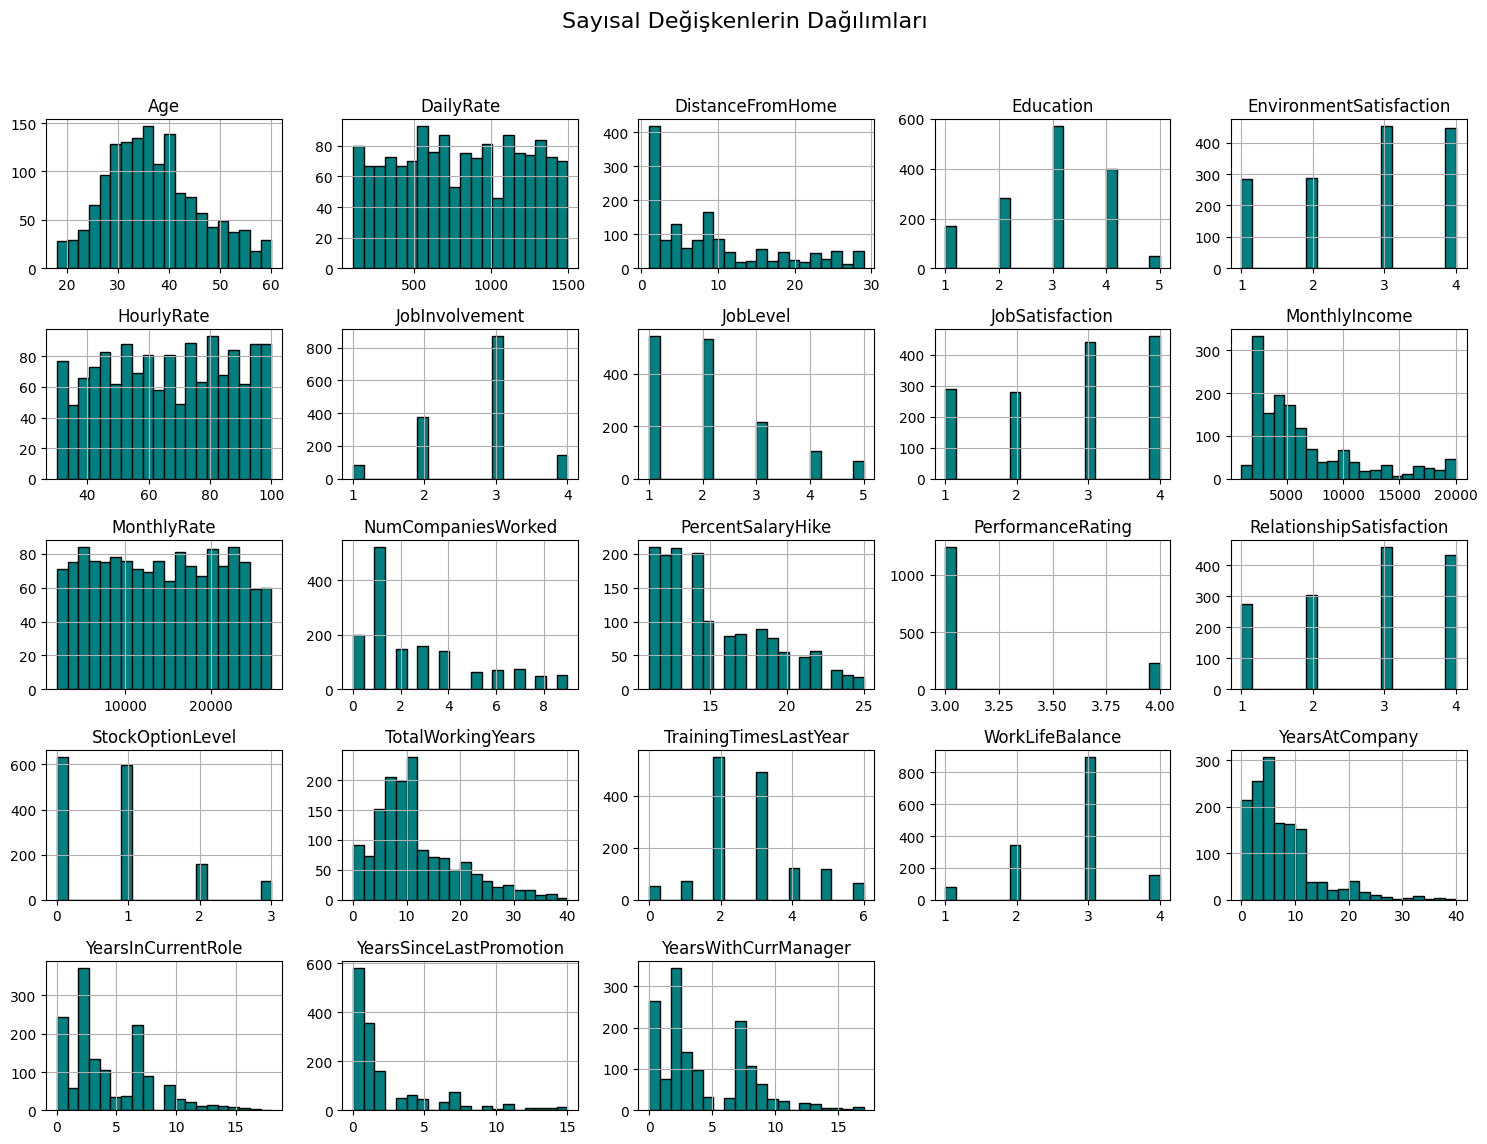

In [5]:
# Tek değerli ve bir şey ifade etmeyen değişkenleri ayırıyoruz.
target_attrition = df['Attrition'] # Kümeleri profillerken kullanmak üzere ayırıyoruz
drop_cols = ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber', 'Attrition']
df = df.drop(columns=drop_cols)

print(f"\nGereksiz kolonlar atıldıktan sonra boyut: {df.shape}")

#Dağılımlara bakıyoruz.
df.hist(figsize=(15, 12), bins=20, color='teal', edgecolor='black')
plt.suptitle("Sayısal Değişkenlerin Dağılımları", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

## 3. Aykırı Değer Tespiti: Isolation Forest

Sayısal değişkenlerin dağılımlarını incelediğimizde sola çarpıklık gözlemledik. Klasik IQR yöntemi yerine, birden fazla değişkenin birbirleriyle olan karmaşık ilişkilerindeki aykırılıkları daha iyi yakalayabilen ve ağaç tabanlı bir yaklaşım sunan **Isolation Forest** algoritmasını kullanarak veri setimizdeki aykırı gözlemleri temizliyoruz. Kümeleme algoritmaları mesafeye (Öklid) duyarlı olduğu için kategorik ve sayısal değişkenleri bu aşamada ayırıyoruz.

In [ ]:
#kullanacağımız clustering modelleri oklid ile mesafe ölçümü yapması sebebiyle sayısal kolonlar ile devam edeceğiz ancak bir modelimiz kategorikler ile de çalışıyor bu sebeple ayrı ayrı nesnelerde tutuyoruz.
# Ordinal değişkenleri (Education, PerformanceRating vb.) dışarıda bırakıyoruz
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object']).columns.tolist()

continuous_cols = [
    'Age', 'MonthlyIncome', 'TotalWorkingYears', 
    'YearsAtCompany', 'DistanceFromHome', 'DailyRate', 
    'HourlyRate', 'MonthlyRate', 'PercentSalaryHike'
] 

iso = IsolationForest(contamination=0.05, random_state=42)
df['Is_Anomaly'] = iso.fit_predict(df[continuous_cols])

# Anomalileri (değeri 1 olanlar) veriden atıyoruz ve indexleri sıfırlıyoruz.
valid_indices = df['Is_Anomaly'] == 1
df = df[valid_indices].drop(columns=['Is_Anomaly']).reset_index(drop=True)

# Hedef değişkenin (Attrition) de aynı satırları tutması için filtreliyoruz
target_attrition = target_attrition[valid_indices].reset_index(drop=True)

print(f"Anomaliler Temizlendikten Sonra Veri Seti Boyutu: {df.shape}")

Anomaliler Temizlendikten Sonra Veri Seti Boyutu: (1396, 30)


## 4. Veri Ölçeklendirme ve Temel Modellerin Kurulması

Mesafe tabanlı çalışan kümeleme algoritmalarının büyük varyanslı değişkenlerden domine edilmesini önlemek adına sayısal verilerimizi standartlaştırıyoruz. 

Optimum küme sayısını belirlemek için **Dirsek Metodu (Elbow Method)** uyguluyoruz ve grafiğe göre en uygun küme sayısının **2** olduğuna karar veriyoruz. Ardından K-Means, Agglomerative Clustering ve Gaussian Mixture modellerini kurarak orijinal veri uzayındaki `Silhouette`, `Davies-Bouldin` ve `Calinski-Harabasz` başarı metriklerini hesaplıyoruz.

In [7]:
#sayısal değerleri ölçeklendiriyoruz. Çünkü çok yüksek sayılara aldanmasın aynı ölçekte olsunlar diye böyle bir dönüşüm yapmamız gerekiyor.
scaler = StandardScaler()
X_scaled_continuous = pd.DataFrame(scaler.fit_transform(df[continuous_cols]), columns=continuous_cols)
#sadece sürekli değişkenler üzeribde pca yapıyruz.
pca = PCA(n_components=2, random_state=42) 
X_pca = pca.fit_transform(X_scaled_continuous)

print(f"PCA Öncesi Sürekli Değişken Sayısı: {X_scaled_continuous.shape[1]} -> PCA Sonrası Boyut: {X_pca.shape[1]}")

# K-Prototypes İçin Veri Kümesi (Sayısal kolonlar ölçekli, kategorikler HAM kalacak)
X_kproto = df.copy()
X_kproto[num_cols] = scaler.fit_transform(X_kproto[num_cols])

PCA Öncesi Sürekli Değişken Sayısı: 9 -> PCA Sonrası Boyut: 2


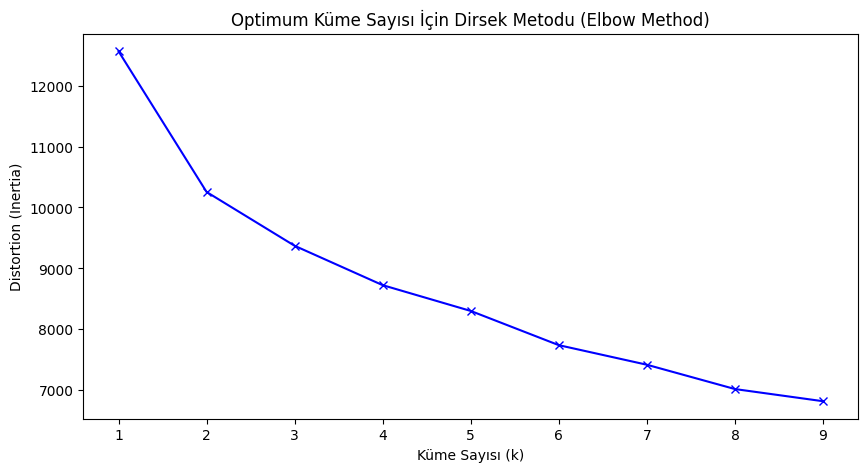

In [8]:
#optimum kümse sayısı için elbow method uyguluyoruz
distortions = []
K = range(1, 10)
for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42)
    kmeanModel.fit(X_scaled_continuous)
    distortions.append(kmeanModel.inertia_)

plt.figure(figsize=(10,5))
plt.plot(K, distortions, 'bx-')
plt.xlabel('Küme Sayısı (k)')
plt.ylabel('Distortion (Inertia)')
plt.title('Optimum Küme Sayısı İçin Dirsek Metodu (Elbow Method)')
plt.show()

In [9]:
n_clusters = 2# Not: PCA sonrası dirsek grafiğine tekrar bakarak bu rakamı güncelleyebilirsin.

# TÜM MODELLERDE X_scaled YERİNE X_pca KULLANILACAK
# 1. K-Means
kmeans = KMeans(n_clusters=n_clusters, init='k-means++', n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled_continuous)

# 2. Agglomerative Clustering
agglo = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
agglo_labels = agglo.fit_predict(X_scaled_continuous)

# 3. Gaussian Mixture Model
gmm = GaussianMixture(n_components=n_clusters, covariance_type='full', random_state=42)
gmm_labels = gmm.fit_predict(X_scaled_continuous)

# Metrik Karşılaştırma Fonksiyonu
def evaluate_clusters(X, labels, model_name):
    sil = silhouette_score(X, labels)
    db = davies_bouldin_score(X, labels)
    ch = calinski_harabasz_score(X, labels)
    return {"Model": model_name, "Silhouette (↑)": sil, "Davies-Bouldin (↓)": db, "Calinski-Harabasz (↑)": ch}

results = []
results.append(evaluate_clusters(X_scaled_continuous, kmeans_labels, "K-Means"))
results.append(evaluate_clusters(X_scaled_continuous, agglo_labels, "Agglomerative"))
results.append(evaluate_clusters(X_scaled_continuous, gmm_labels, "Gaussian Mixture"))

res_df = pd.DataFrame(results)
display(res_df)

,Model,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑)
0,K-Means,0.231303,1.787784,313.992280
1,Agglomerative,0.282165,1.529851,273.877203
2,Gaussian Mixture,0.162121,2.281178,233.975863


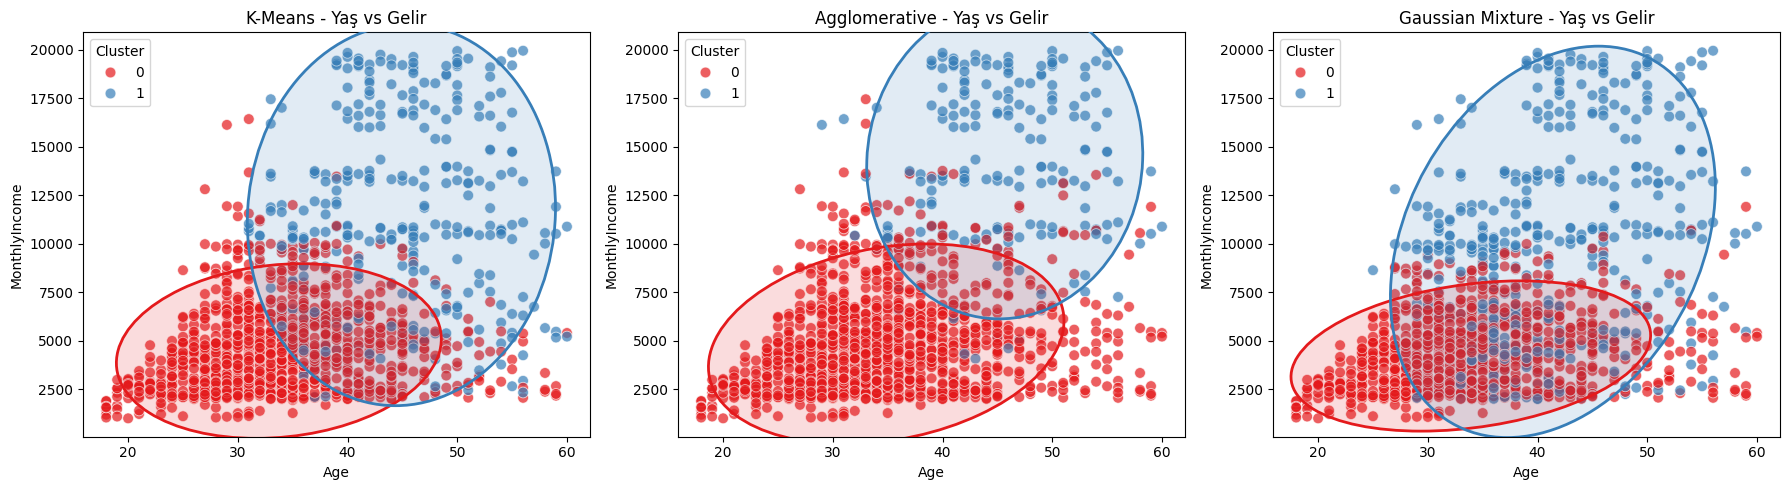

In [10]:
vis_x = df['Age'] 
vis_y = df['MonthlyIncome']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
models = ["K-Means", "Agglomerative", "Gaussian Mixture"]
labels_list = [kmeans_labels, agglo_labels, gmm_labels]

#kümeler için renk ayarı
n_clusters = len(np.unique(kmeans_labels))
palette = sns.color_palette('Set1', n_colors=n_clusters)

for ax, labels, title in zip(axes, labels_list, models):
    sns.scatterplot(x=vis_x, y=vis_y, hue=labels, palette=palette, ax=ax, s=60, alpha=0.7)
    ax.set_title(f"{title} - Yaş vs Gelir")
    ax.legend(title="Cluster")
    
    # Her küme için kendi renginde elips çizdirme
    for i, cluster_val in enumerate(np.unique(labels)):
        cluster_x = vis_x[labels == cluster_val]
        cluster_y = vis_y[labels == cluster_val]
        
        if len(cluster_x) > 2: # Elips için en az 3 nokta lazım
            cluster_color = palette[i]
            draw_ellipse_aesthetic(cluster_x, cluster_y, ax, color=cluster_color, n_std=2.0)

plt.tight_layout()
plt.show()

## 5. Temel Bileşenler Analizi (PCA) Uygulaması

Orijinal uzayda elde ettiğimiz metrikleri iyileştirmek ve veri setindeki varyansın büyük kısmını açıklayan daha az sayıda bileşenle çalışmak için veri setine **PCA (Principal Component Analysis)** uyguluyoruz. Amacımız, boyutsallık lanetinden kurtularak kümelerin birbirinden daha net ayrışmasını sağlamaktır. PCA sonrası algoritmalarımızı tekrar eğitiyor ve sonuçları karşılaştırıyoruz.

PCA Öncesi ve Sonrası Model Performansları:


,Model,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑)
0,K-Means,0.231303,1.787784,313.992280
1,Agglomerative,0.282165,1.529851,273.877203
2,Gaussian Mixture,0.162121,2.281178,233.975863
3,K-Means (PCA),0.461481,0.851048,1184.640837
4,Agglomerative (PCA),0.477974,0.749179,1028.136763
5,Gaussian Mixture (PCA),0.491509,0.752241,1126.376245


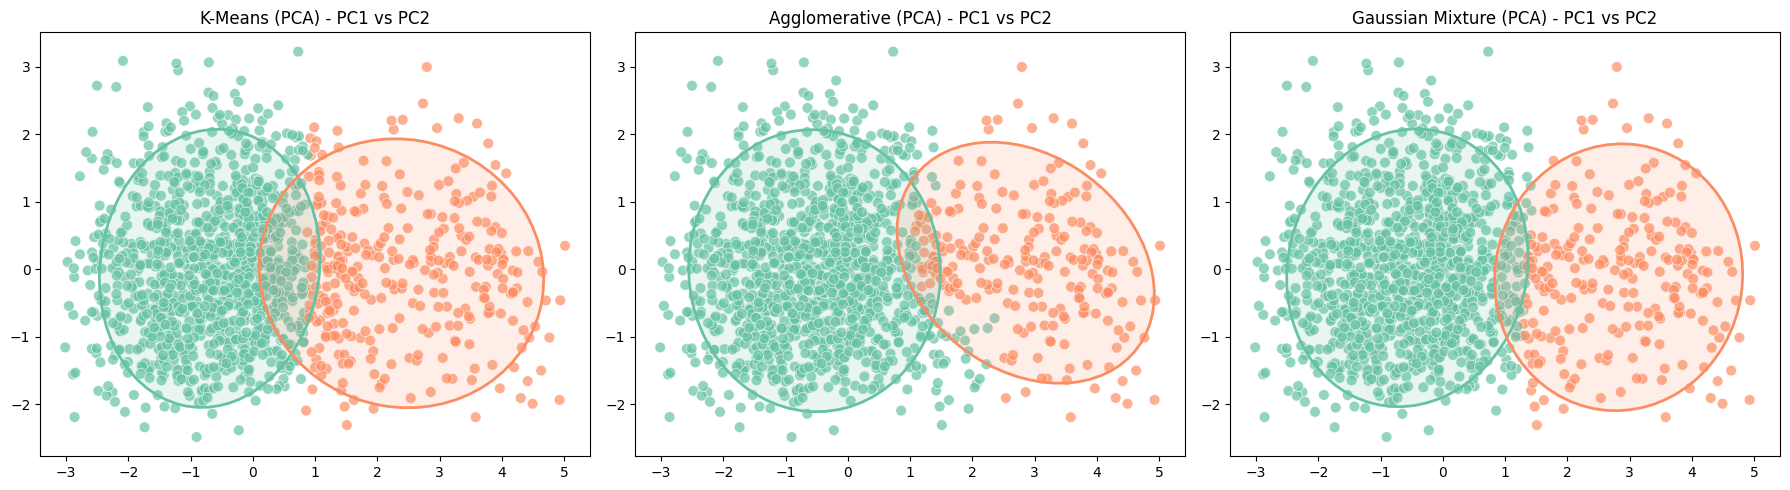

In [11]:
# PCA Verisi Üzerinde Modeller
kmeans_pca_labels = kmeans.fit_predict(X_pca)
agglo_pca_labels = agglo.fit_predict(X_pca)
gmm_pca_labels = gmm.fit_predict(X_pca)

results_pca = []
results_pca.append(evaluate_clusters(X_pca, kmeans_pca_labels, "K-Means (PCA)"))
results_pca.append(evaluate_clusters(X_pca, agglo_pca_labels, "Agglomerative (PCA)"))
results_pca.append(evaluate_clusters(X_pca, gmm_pca_labels, "Gaussian Mixture (PCA)"))

res_pca_df = pd.DataFrame(results_pca)
print("PCA Öncesi ve Sonrası Model Performansları:")
display(pd.concat([res_df, res_pca_df]).reset_index(drop=True))

# PCA Görselleştirmeleri (Elipsli)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
labels_list_pca = [kmeans_pca_labels, agglo_pca_labels, gmm_pca_labels]
models = ["K-Means", "Agglomerative", "Gaussian Mixture"]
palette = sns.color_palette('Set2', n_clusters)

for ax, labels, title in zip(axes, labels_list_pca, models):
    sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels, palette=palette, ax=ax, s=60, alpha=0.7)
    ax.set_title(f"{title} (PCA) - PC1 vs PC2")
    if ax.legend_:
        ax.legend_.remove()
    
    for idx, cluster_val in enumerate(np.unique(labels)):
        cluster_x = X_pca[labels == cluster_val, 0]
        cluster_y = X_pca[labels == cluster_val, 1]
        current_cluster_color = palette[idx]
        draw_ellipse_aesthetic(cluster_x, cluster_y, ax, color=current_cluster_color, n_std=2.0)

plt.tight_layout()
plt.show()

## 6. Hibrit Veriler İçin K-Prototypes Algoritması

Önceki modellerde temel olarak mesafe tabanlı yaklaşımlar sergiledik ancak veri setimizde ciddi miktarda kategorik değişken de bulunuyor. Sayısal ve kategorik verilerin bir arada olduğu hibrit yapılar için tasarlanmış **K-Prototypes** algoritmasını da sürecimize dahil ediyoruz. Modeli hem orijinal uzayda hem de PCA uygulanmış uzayda test ederek sonuçları gözlemliyoruz.

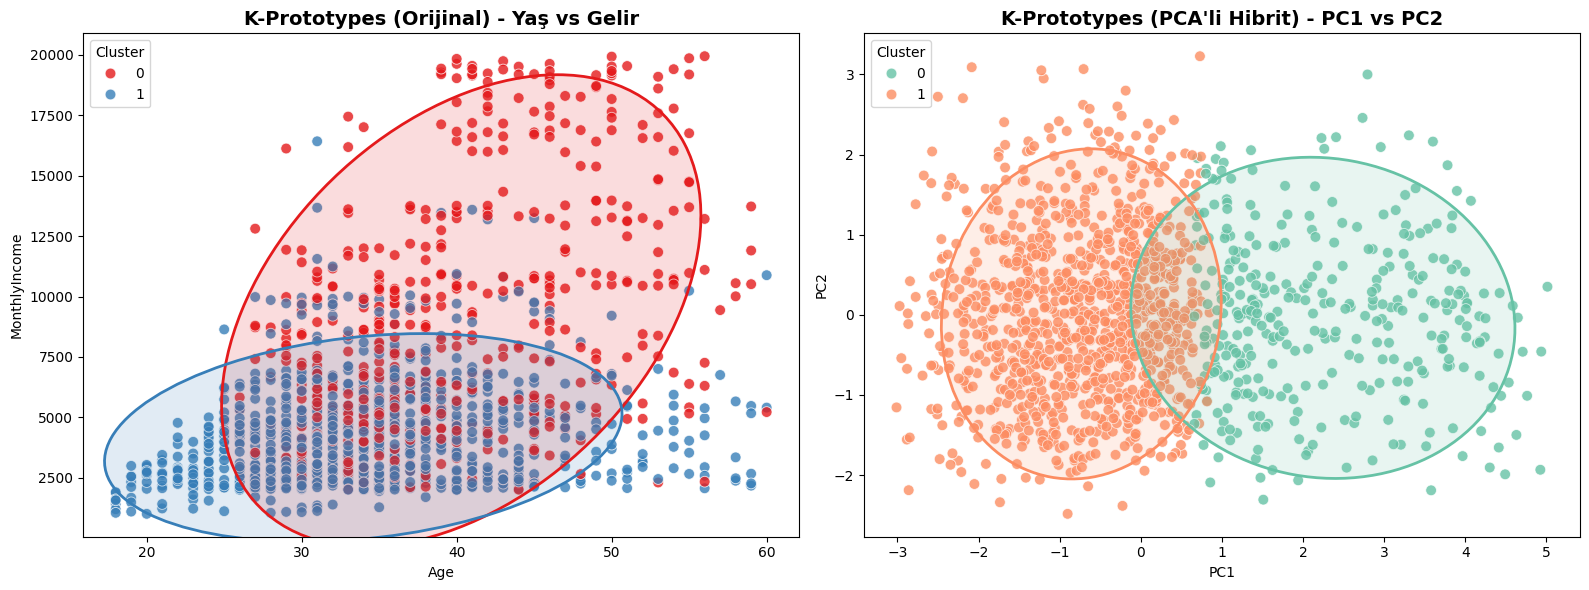

In [12]:
# K-Prototypes Kategorik İndeksleri İstiyor
cat_indices = [X_kproto.columns.get_loc(col) for col in cat_cols]

# PCAsiz orjinal veri ile 
kproto = KPrototypes(n_clusters=n_clusters, init='Cao', n_jobs=-1, random_state=42)
kproto_labels = kproto.fit_predict(X_kproto.values, categorical=cat_indices)

# CA'li K-Prototypes (sayısal + kategorik)
df_pca_nums = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
# İndeks uyuşmazlığını önlemek için categorik verilerin indeksini sıfırlıyoruz
X_kproto_pca = pd.concat([df_pca_nums, df[cat_cols].reset_index(drop=True)], axis=1)

# PCA verisi için yeni kategorik indeksler
cat_indices_pca = [X_kproto_pca.columns.get_loc(col) for col in cat_cols]

kproto_pca = KPrototypes(n_clusters=n_clusters, init='Cao', n_jobs=-1, random_state=42)
kproto_pca_labels = kproto_pca.fit_predict(X_kproto_pca.values, categorical=cat_indices_pca)

# GÖRSELLEŞTİRME
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Kümeler için uyumlu renk paletleri tanımlayalım
palette_orig = sns.color_palette('Set1', n_colors=n_clusters)
palette_pca = sns.color_palette('Set2', n_colors=n_clusters)

# Non-PCA Plot
sns.scatterplot(x=vis_x, y=vis_y, hue=kproto_labels, palette=palette_orig, ax=axes[0], s=60, alpha=0.8)
axes[0].set_title("K-Prototypes (Orijinal) - Yaş vs Gelir", fontsize=14, fontweight='bold')
axes[0].legend(title="Cluster", loc='upper left')

for i, cluster_val in enumerate(np.unique(kproto_labels)):
    cluster_x = vis_x[kproto_labels == cluster_val]
    cluster_y = vis_y[kproto_labels == cluster_val]
    if len(cluster_x) > 2:
        draw_ellipse_aesthetic(cluster_x, cluster_y, axes[0], color=palette_orig[i], n_std=2.0)

# PCA Plot
sns.scatterplot(x=X_kproto_pca['PC1'], y=X_kproto_pca['PC2'], hue=kproto_pca_labels, palette=palette_pca, ax=axes[1], s=60, alpha=0.8)
axes[1].set_title("K-Prototypes (PCA'li Hibrit) - PC1 vs PC2", fontsize=14, fontweight='bold')
axes[1].legend(title="Cluster", loc='upper left')

for i, cluster_val in enumerate(np.unique(kproto_pca_labels)):
    cluster_x = X_kproto_pca['PC1'][kproto_pca_labels == cluster_val]
    cluster_y = X_kproto_pca['PC2'][kproto_pca_labels == cluster_val]
    if len(cluster_x) > 2:
        draw_ellipse_aesthetic(cluster_x, cluster_y, axes[1], color=palette_pca[i], n_std=2.0)

plt.tight_layout()
plt.show()


In [13]:
#k-prototypes modelin başarı metrikleri
sil_orig = silhouette_score(X_kproto[num_cols], kproto_labels)
db_orig = davies_bouldin_score(X_kproto[num_cols], kproto_labels)

# K-Prototypes PCA Skorları (PC1 ve PC2 Uzayında)
sil_pca = silhouette_score(df_pca_nums, kproto_pca_labels)
db_pca = davies_bouldin_score(df_pca_nums, kproto_pca_labels)

kproto_results = pd.DataFrame([
    {"Model": "K-Prototypes (Orijinal Uzay)", "Silhouette (↑)": round(sil_orig, 4), "Davies-Bouldin (↓)": round(db_orig, 4)},
    {"Model": "K-Prototypes (PCA Uzayı)", "Silhouette (↑)": round(sil_pca, 4), "Davies-Bouldin (↓)": round(db_pca, 4)}
])

display(kproto_results)

,Model,Silhouette (↑),Davies-Bouldin (↓)
0,K-Prototypes (Orijinal Uzay),0.1373,2.4852
1,K-Prototypes (PCA Uzayı),0.4476,0.8857


## 7. Model Seçimi ve Profil Çıkarımı

Metrik tablolarını karşılaştırdığımızda kümeleri en iyi şekilde ayrıştıran ve en yüksek Silhouette skorunu veren modelin **Gaussian Mixture (PCA)** olduğunu tespit ettik. Nihai etiketlemeyi bu modelin oluşturduğu 2 küme üzerinden gerçekleştiriyoruz.

Şimdi bu kümelerin ortalama özelliklerini (Yaş, Maaş, Kıdem vb.) ve başta ayırdığımız `Attrition` değişkeni ile çaprazlayarak işten ayrılma oranlarını inceliyoruz. Modelin ayrım yaparken en çok ağırlık verdiği değişkenleri önem sırasına göre listeliyoruz.

,Age,MonthlyIncome,TotalWorkingYears,YearsAtCompany,DistanceFromHome,DailyRate,HourlyRate,MonthlyRate,PercentSalaryHike,Attrition_Rate (%)
Cluster_Label,,,,,,,,,,
0,34.32,4678.23,8.15,5.25,9.22,804.99,66.12,14169.51,15.30,18.07
1,45.81,12845.64,21.74,12.14,7.74,802.70,63.59,15085.66,14.31,7.69


TotalWorkingYears    0.583366
MonthlyIncome        0.524381
Age                  0.442891
YearsAtCompany       0.425174
PercentSalaryHike    0.059771
Name: PC1, dtype: float64

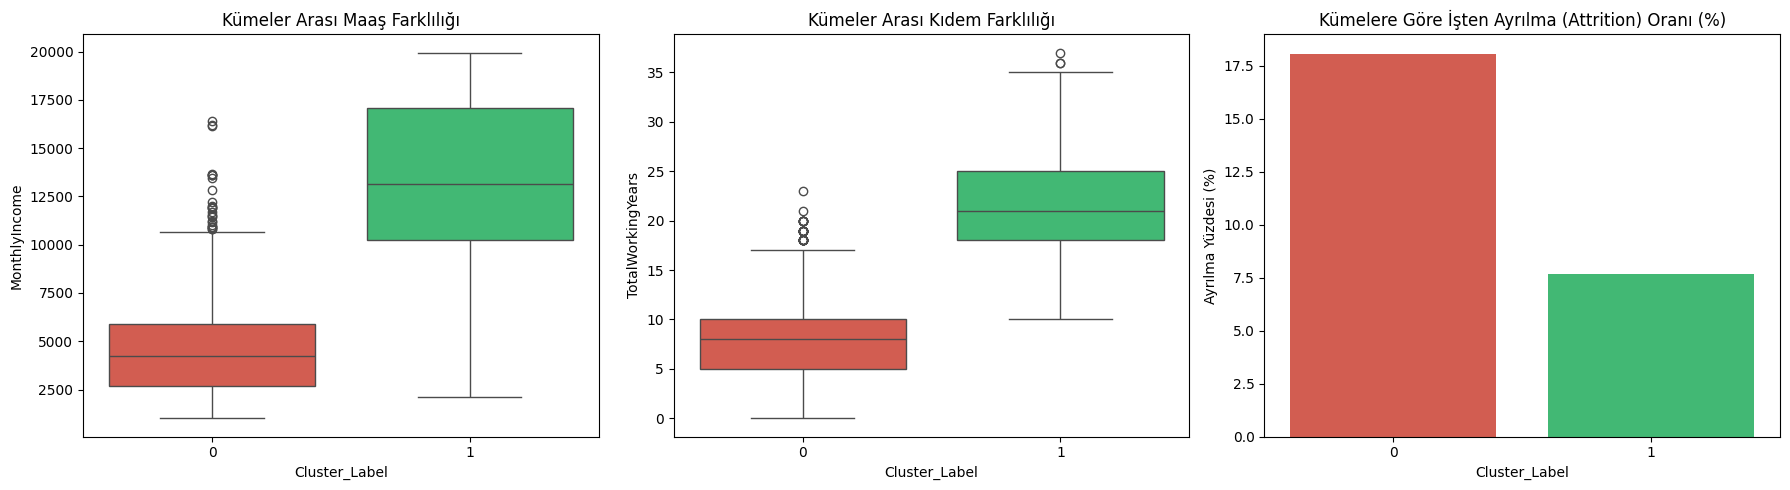

In [14]:
#küme profillerini dataframein içine entegre ediyoruz.
df['Cluster_Label'] = gmm_pca_labels

# Kenara ayırdığımız Attrition verisini ekliyoruz
df['Attrition'] = target_attrition

# 'Yes' -> 1, 'No' -> 0 dönüşümü yapıyoruz ki ortalama alabildikçe YÜZDE (%) çıksın
df['Attrition_Numeric'] = df['Attrition'].apply(lambda x: 1 if x == 'Yes' else 0)

# Sürekli değişkenlerin ortalaması ve Attrition oranını aynı anda alıyoruz.
profiling_cols = continuous_cols + ['Attrition_Numeric']
cluster_summary = df.groupby('Cluster_Label')[profiling_cols].mean()

# Attrition_Numeric sütununu % formatında göstermek için 100 ile çarpalım
cluster_summary['Attrition_Rate (%)'] = cluster_summary['Attrition_Numeric'] * 100
cluster_summary = cluster_summary.drop(columns=['Attrition_Numeric'])


display(cluster_summary.round(2))

#en önemli bileşenleri gösteriyoruz.
pca_loadings = pd.DataFrame(
    pca.components_.T, 
    index=continuous_cols, 
    columns=[f'PC{i+1}' for i in range(pca.n_components_)]
)

top_features_pc1 = pca_loadings['PC1'].abs().sort_values(ascending=False).head(5)
display(top_features_pc1)

#  GÖRSELLEŞTİRME 
plt.figure(figsize=(18, 5))

#kümelerin renk ayarlarını baştan yapıyoruz.
custom_palette = {
    0: '#e74c3c', 1: '#2ecc71', 2: '#3498db',
    '0': '#e74c3c', '1': '#2ecc71', '2': '#3498db'
}

plt.subplot(1, 3, 1)
sns.boxplot(
    x='Cluster_Label', 
    y='MonthlyIncome', 
    data=df, 
    hue='Cluster_Label', 
    palette=custom_palette,
    legend=False
)
plt.title('Kümeler Arası Maaş Farklılığı')

plt.subplot(1, 3, 2)
sns.boxplot(
    x='Cluster_Label', 
    y='TotalWorkingYears', 
    data=df, 
    hue='Cluster_Label',
    palette=custom_palette,
    legend=False
)
plt.title('Kümeler Arası Kıdem Farklılığı')

plt.subplot(1, 3, 3)
attrition_rates = df.groupby('Cluster_Label')['Attrition_Numeric'].mean() * 100

sns.barplot(
    x=attrition_rates.index, 
    y=attrition_rates.values, 
    hue=attrition_rates.index, 
    palette=custom_palette,
    legend=False
)
plt.title('Kümelere Göre İşten Ayrılma (Attrition) Oranı (%)')
plt.ylabel('Ayrılma Yüzdesi (%)')

plt.tight_layout()
plt.show()

## 8. Değerlendirme ve Sonuç

Oluşturulan kümeler İnsan Kaynakları iş bilgisi perspektifiyle değerlendirildiğinde mantıklı ve beklenen sonuçlar vermiştir:
* **Küme 0 (%18.07 Ayrılma Oranı):** Yaşça daha genç, şirket içi kıdemi ve toplam deneyimi düşük, aynı zamanda aylık gelirleri ortalamanın altında kalan çalışan grubudur. Bu grubun turnover (işten ayrılma) riski belirgin şekilde yüksektir.
* **Küme 1 (%7.69 Ayrılma Oranı):** Şirkette daha uzun süredir çalışan, ev-iş mesafesi daha kısa olan, yaşı ve kıdemiyle doğru orantılı olarak daha yüksek maaşlı profillerdir. Bağlılık oranları çok daha yüksektir.

**Aksiyon Önerisi:** Elde edilen bu çıktılar, özellikle "Küme 0" profiline uyan personellere yönelik yetenek tutma, kariyer planlaması ve ücret politikalarının yeniden değerlendirilmesi gibi stratejik İK kararlarında doğrudan bir yönlendirici olarak kullanılabilir.